In [1]:
# Helper function for visualization.
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt

def visualize_graph(G, color):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=42), with_labels=False,
                     node_color=color, cmap="Set2")
    plt.show()

def visualize_embedding(h, color, epoch=None, loss=None):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    h = h.detach().cpu().numpy()
    plt.scatter(h[:, 0], h[:, 1], s=140, c=color, cmap="Set2")
    if epoch is not None and loss is not None:
        plt.xlabel(f'Epoch: {epoch}, Loss: {loss.item():.4f}', fontsize=16)
    plt.show()

# 소개: 그래프 신경망 (Graph Neural Networks; GNN) 

최근 그래프를 대상으로 하는 딥러닝은 딥러닝 분야에서 가장 활발히 연구되는 주제 중 하나로 떠올랐습니다.
그래프 신경망(Graph Neural Networks, GNN)은 기존 딥러닝 개념을 이미지나 텍스트와 달리 불규칙한 구조를 가진 데이터로 확장하고, 신경망이 객체와 객체 간의 관계를 추론할 수 있도록 하는 것을 목표로 합니다.

이를 위해 간단한 **신경망 메시지 전달 방식**을 사용합니다. 그래프 $\mathcal{G} = (\mathcal{V}, \mathcal{E})$의 모든 노드 $v \in \mathcal{V}$에 대해, 이웃 노드 $\mathcal{N}(v)$의 국소적인 정보를 집계하여 노드 특징 $\mathbf{x}_v^{(\ell)}$을 반복적으로 갱신합니다.

$$
\mathbf{x}_v^{(\ell + 1)} = f^{(\ell + 1)}_{\theta} \left( \mathbf{x}_v^{(\ell)}, \left\{ \mathbf{x}_w^{(\ell)} : w \in \mathcal{N}(v) \right\} \right)
$$

이 튜토리얼에서는 **[PyTorch Geometric(PyG) 라이브러리](https://github.com/rusty1s/pytorch_geometric)** 기반의 그래프 신경망을 통해 그래프 딥러닝의 기본 개념을 소개합니다.
PyTorch Geometric은 널리 사용되는 딥러닝 프레임워크인 [PyTorch](https://pytorch.org/)의 확장 라이브러리로, 그래프 신경망을 쉽게 구현할 수 있도록 다양한 기법과 유틸리티를 제공합니다.

[Kipf 등의 연구(2017)](https://arxiv.org/abs/1609.02907)를 바탕으로, 잘 알려진 [**Zachary의 가라테 클럽 네트워크**](https://en.wikipedia.org/wiki/Zachary%27s_karate_club)라는 간단한 그래프 예제를 살펴보며 GNN을 알아보겠습니다. 이 그래프는 가라테 클럽 회원 34명의 소셜 네트워크를 나타내며, 클럽 밖에서 교류한 회원 간의 연결을 기록합니다. 여기서는 회원 간의 상호작용으로 형성된 커뮤니티를 탐지하는 데 관심을 둡니다.

PyTorch Geometric에서는 [`torch_geometric.datasets`](https://pytorch-geometric.readthedocs.io/en/latest/modules/datasets.html#torch_geometric.datasets) 하위 패키지를 통해 이 데이터셋을 쉽게 불러올 수 있습니다.

In [1]:
from torch_geometric.datasets import KarateClub
import torch

dataset = KarateClub()
print(f'Dataset: {dataset}:')
print('======================')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

c:\Users\KETI\anaconda3\envs\ai_tutorial\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: KarateClub():
Number of graphs: 1
Number of features: 34
Number of classes: 4


[`KarateClub`](https://pytorch-geometric.readthedocs.io/en/latest/modules/datasets.html#torch_geometric.datasets.KarateClub) 데이터셋을 초기화한 후, 먼저 몇 가지 속성을 살펴보겠습니다.
이 데이터셋에는 정확히 **하나의 그래프**가 있으며, 각 노드에는 가라테 클럽 회원을 고유하게 나타내는 **34차원 특징 벡터**가 할당되어 있습니다.
또한 그래프에는 각 노드가 속한 커뮤니티를 나타내는 **4개의 클래스**가 있습니다.

이제 그래프를 더 자세히 살펴보겠습니다.

In [2]:
data = dataset[0]  # Get the first graph object.

val_node_indices = torch.where(data.train_mask == True)[0]+2

val_mask = torch.zeros(data.y.size(0), dtype=torch.bool)
for i in val_node_indices:
    val_mask[i.item()] = True
    
test_node_indices = torch.where((data.train_mask == False) & (val_mask == False))[0]
test_mask = torch.zeros(data.y.size(0), dtype=torch.bool)
for i in test_node_indices:
    test_mask[i.item()] = True
    
data.val_mask = val_mask
data.test_mask = test_mask

print(data)
print('==============================================================')

# Gather some statistics about the graph.
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Average node degree: {data.num_edges / data.num_nodes:.2f}')
print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Training node label rate: {int(data.train_mask.sum()) / data.num_nodes:.2f}')
#print(f'Has isolated nodes: {data.has_isolated_nodes()}')
#print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')

Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34], val_mask=[34], test_mask=[34])
Number of nodes: 34
Number of edges: 156
Average node degree: 4.59
Number of training nodes: 4
Training node label rate: 0.12
Is undirected: True


In [3]:
print(data.x)
print(data.y)

tensor([[1., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.],
        [0., 0., 1.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 1., 0., 0.],
        [0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.]])
tensor([1, 1, 1, 1, 3, 3, 3, 1, 0, 1, 3, 1, 1, 1, 0, 0, 3, 1, 0, 1, 0, 1, 0, 0,
        2, 2, 0, 0, 2, 0, 0, 2, 0, 0])


PyTorch Geometric에서 각 그래프는 그래프 표현에 필요한 모든 정보를 담은 하나의 [`Data`](https://pytorch-geometric.readthedocs.io/en/latest/modules/data.html#torch_geometric.data.Data) 객체로 표현됩니다.
언제든지 `print(data)`로 데이터 객체를 출력하여 속성과 각 속성의 형태를 간단히 확인할 수 있습니다.
```
Data(edge_index=[2, 156], x=[34, 34], y=[34], train_mask=[34])
```
이 `data` 객체에는 다음과 같은 4개의 속성이 있습니다.
(1) `edge_index`는 **그래프의 연결 정보**, 즉 각 엣지의 출발 노드와 도착 노드 인덱스 쌍을 저장합니다.
PyG에서는 (2) **노드 특징**을 `x`로 표현하고(34개 노드 각각에 34차원 특징 벡터가 할당됨), (3) **노드 레이블**을 `y`로 표현합니다(각 노드는 정확히 하나의 클래스에 속함).
(4) 추가 속성인 `train_mask`는 어떤 노드의 커뮤니티 소속을 이미 알고 있는지 나타냅니다.
전체 노드 중 정답 레이블을 알고 있는 노드는 커뮤니티마다 하나씩, 총 4개뿐이며, 나머지 노드의 커뮤니티 소속을 추론하는 것이 목표입니다.

`data` 객체는 그래프의 기본 속성을 확인할 수 있는 **유틸리티 함수**도 제공합니다.
예를 들어, 그래프에 고립 노드가 있는지(어떤 노드와도 연결된 엣지가 없는 노드), 자기 루프가 있는지($(v, v) \in \mathcal{E}$), 또는 무방향 그래프인지(모든 엣지 $(v, w) \in \mathcal{E}$에 대해 역방향 엣지 $(w, v) \in \mathcal{E}$도 존재함)를 쉽게 확인할 수 있습니다.

이제 `edge_index` 속성을 더 자세히 살펴보겠습니다.

In [4]:
from IPython.display import Javascript  # Restrict height of output cell.
#display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 300})'''))

edge_index = data.edge_index
print(edge_index)

tensor([[ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,
          1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,
          3,  3,  3,  3,  3,  4,  4,  4,  5,  5,  5,  5,  6,  6,  6,  6,  7,  7,
          7,  7,  8,  8,  8,  8,  8,  9,  9, 10, 10, 10, 11, 12, 12, 13, 13, 13,
         13, 13, 14, 14, 15, 15, 16, 16, 17, 17, 18, 18, 19, 19, 19, 20, 20, 21,
         21, 22, 22, 23, 23, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 27, 27,
         27, 27, 28, 28, 28, 29, 29, 29, 29, 30, 30, 30, 30, 31, 31, 31, 31, 31,
         31, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 33, 33, 33, 33,
         33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33],
        [ 1,  2,  3,  4,  5,  6,  7,  8, 10, 11, 12, 13, 17, 19, 21, 31,  0,  2,
          3,  7, 13, 17, 19, 21, 30,  0,  1,  3,  7,  8,  9, 13, 27, 28, 32,  0,
          1,  2,  7, 12, 13,  0,  6, 10,  0,  6, 10, 16,  0,  4,  5, 16,  0,  1,
          2,  3,  0,  2, 30, 32, 33,  2, 33,  0,  4

`edge_index`를 출력하면 PyG가 내부적으로 그래프의 연결 정보를 어떻게 표현하는지 알 수 있습니다.
각 엣지에 대해 `edge_index`는 두 개의 노드 인덱스 쌍을 저장합니다. 첫 번째 값은 엣지의 출발 노드 인덱스이고, 두 번째 값은 도착 노드 인덱스입니다.

이 표현 방식은 희소 행렬을 나타낼 때 흔히 사용하는 **COO 형식(좌표 형식)**입니다.
PyG는 인접 정보를 밀집 행렬 $\mathbf{A} \in \{ 0, 1 \}^{|\mathcal{V}| \times |\mathcal{V}|}$로 저장하는 대신, $\mathbf{A}$에서 값이 0이 아닌 항목의 좌표와 값만 저장하는 희소 표현을 사용합니다.

PyG는 방향 그래프와 무방향 그래프를 별도의 형식으로 구분하지 않습니다. 무방향 그래프는 `edge_index`의 모든 엣지에 대해 역방향 엣지가 존재하는 방향 그래프의 특수한 경우로 취급합니다.

그래프를 `networkx` 라이브러리 형식으로 변환하여 시각화할 수도 있습니다. 이 라이브러리는 그래프 조작 기능뿐 아니라 강력한 시각화 도구도 제공합니다.

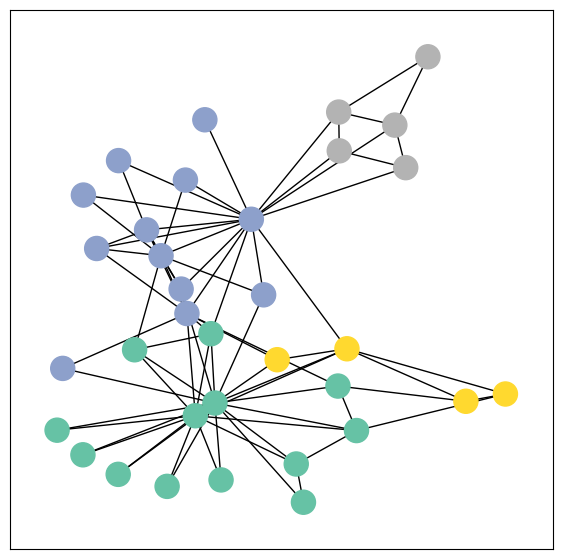

In [6]:
from torch_geometric.utils import to_networkx

G = to_networkx(data, to_undirected=True)
visualize_graph(G, color=data.y)

## 그래프 신경망 구현하기

PyG의 데이터 처리 방식을 살펴보았으니, 이제 첫 번째 그래프 신경망을 구현해 보겠습니다!

이를 위해 가장 간단한 GNN 연산자 중 하나인 **GCN 계층**([Kipf 등의 연구(2017)](https://arxiv.org/abs/1609.02907))을 사용합니다. 이 계층은 다음과 같이 정의됩니다.

$$
\mathbf{x}_v^{(\ell + 1)} = \mathbf{W}^{(\ell + 1)} \sum_{w \in \mathcal{N}(v) \, \cup \, \{ v \}} \frac{1}{c_{w,v}} \cdot \mathbf{x}_w^{(\ell)}
$$

여기서 $\mathbf{W}^{(\ell + 1)}$은 형태가 `[num_output_features, num_input_features]`인 학습 가능한 가중치 행렬이고, $c_{w,v}$는 각 엣지에 대한 고정된 정규화 계수입니다.

PyG는 이 계층을 [`GCNConv`](https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html#torch_geometric.nn.conv.GCNConv)로 구현합니다. 노드 특징 표현 `x`와 COO 형식의 그래프 연결 정보 `edge_index`를 전달하여 실행할 수 있습니다.

이제 `torch.nn.Module` 클래스에 신경망 구조를 정의하여 첫 번째 그래프 신경망을 만들어 보겠습니다.

In [5]:
import torch
from torch.nn import Linear
from torch_geometric.nn import GCNConv
import torch.nn.functional as F

import random

def seed_everything(seed):
    """ Set random seeds for reproducibility.
    Args:
        seed (int): Random seed.
    """
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(dataset.num_features, 4)
        self.conv2 = GCNConv(4, 4)
        self.conv3 = GCNConv(4, 2)
        self.classifier = Linear(2, dataset.num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = h.relu()
        h = self.conv2(h, edge_index)
        h = h.relu()
        h = self.conv3(h, edge_index)
        h = h.relu()  # Final GNN embedding space.
        
        # Apply a final (linear) classifier.
        out = self.classifier(h)

        return out, h

seed_everything(42)
model = GCN()
print(model)

GCN(
  (conv1): GCNConv(34, 4)
  (conv2): GCNConv(4, 4)
  (conv3): GCNConv(4, 2)
  (classifier): Linear(in_features=2, out_features=4, bias=True)
)


먼저 `__init__`에서 모든 구성 요소를 초기화하고, `forward`에서 신경망의 연산 흐름을 정의합니다.
**세 개의 그래프 합성곱 계층**을 정의하고 쌓으면, 각 노드 주변의 3홉 이웃 정보(최대 세 번의 엣지 이동으로 도달할 수 있는 모든 노드의 정보)를 집계할 수 있습니다.
또한 `GCNConv` 계층을 통해 노드 특징의 차원을 $34 \rightarrow 4 \rightarrow 4 \rightarrow 2$와 같이 $2$차원으로 줄입니다. 각 `GCNConv` 계층에는 [tanh](https://pytorch.org/docs/stable/generated/torch.nn.Tanh.html?highlight=tanh#torch.nn.Tanh) 비선형 활성화 함수를 적용합니다.

그다음 단일 선형 변환([`torch.nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html?highlight=linear#torch.nn.Linear))을 적용합니다. 이 변환은 각 노드를 4개의 클래스 또는 커뮤니티 중 하나로 분류하는 분류기 역할을 합니다.

최종 분류기의 출력과 GNN이 생성한 최종 노드 임베딩을 모두 반환합니다.
`GCN()`으로 모델을 초기화한 뒤 모델을 출력하면, 사용된 모든 하위 모듈의 구성을 확인할 수 있습니다.


### 가라테 클럽 네트워크의 임베딩

GNN이 생성한 노드 임베딩을 살펴보겠습니다.
초기 노드 특징 `x`와 그래프 연결 정보 `edge_index`를 모델에 입력하고, 모델이 생성한 2차원 임베딩을 시각화합니다.

Embedding shape: [34, 2]


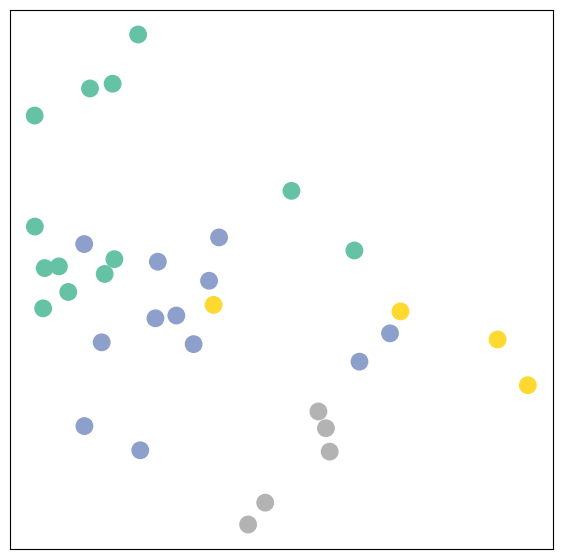

In [8]:
model = GCN()

_, h = model(data.x, data.edge_index)
print(f'Embedding shape: {list(h.shape)}')

visualize_embedding(h, color=data.y)

놀랍게도 모델의 가중치를 학습하기 전부터 그래프의 커뮤니티 구조와 매우 유사한 노드 임베딩이 생성됩니다.
모델의 가중치를 **완전히 무작위로** 초기화했고 아직 학습을 수행하지 않았는데도, 같은 색(같은 커뮤니티)의 노드들이 임베딩 공간에서 이미 서로 가깝게 모여 있습니다!
이를 통해 GNN이 강한 귀납적 편향을 가지며, 입력 그래프에서 서로 가까운 노드들이 비슷한 임베딩을 갖도록 유도한다는 것을 알 수 있습니다.

### 가라테 클럽 네트워크로 학습하기

성능을 더 높일 수 있을까요? 그래프에서 커뮤니티 소속을 알고 있는 노드 4개(커뮤니티마다 하나씩)를 이용해 신경망의 매개변수를 학습하는 예제를 살펴보겠습니다.

모델의 모든 연산은 미분 가능하며 매개변수로 표현되어 있으므로, 일부 레이블을 제공하여 모델을 학습하고 임베딩이 어떻게 변하는지 관찰할 수 있습니다.
여기서는 준지도 학습 또는 트랜스덕티브 학습 방식을 사용합니다. 클래스마다 하나의 노드만 학습 대상으로 삼지만, 입력 그래프 전체의 데이터를 활용할 수 있습니다.

모델 학습 방식은 다른 PyTorch 모델과 매우 유사합니다.
신경망 구조를 정의하는 것 외에 손실 함수(여기서는 [`CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html))를 정의하고, 확률적 경사 기반 최적화 알고리즘(여기서는 [`Adam`](https://pytorch.org/docs/stable/optim.html?highlight=adam#torch.optim.Adam))을 초기화합니다.
그다음 여러 차례 최적화를 수행합니다. 매 단계에서 순전파와 역전파를 수행하여, 순전파로 계산한 손실에 대한 모델 매개변수의 기울기를 구합니다.
PyTorch를 사용해 본 적이 있다면 익숙한 방식일 것입니다.
처음이라면 PyTorch 문서의 [신경망 학습 입문 자료](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html#define-a-loss-function-and-optimizer)를 참고할 수 있습니다.

다음 코드가 준지도 학습을 구현한다는 점에 주목하세요.
```
loss = criterion(out[data.train_mask], data.y[data.train_mask])
```
모든 노드의 임베딩을 계산하지만, **손실 계산에는 학습용 노드만 사용합니다**.
이를 위해 분류기의 출력 `out`과 정답 레이블 `data.y`에서 `train_mask`에 해당하는 노드만 선택합니다.

이제 학습을 시작하고, 학습이 진행됨에 따라 노드 임베딩이 어떻게 변하는지 살펴보겠습니다. 코드를 직접 실행하면 변화를 가장 잘 확인할 수 있습니다.

In [6]:
import time
from IPython.display import Javascript  # Restrict height of output cell.
#display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 430})'''))

model = GCN()
criterion = torch.nn.CrossEntropyLoss()  # Define loss criterion.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # Define optimizer.

def train(data):
    optimizer.zero_grad()  # Clear gradients.
    out, h = model(data.x, data.edge_index)  # Perform a single forward pass.
    loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Compute the loss solely based on the training nodes.
    loss.backward()  # Derive gradients.
    optimizer.step()  # Update parameters based on gradients.
    return loss, h

embedding_history = []
epoch_history = []
loss_history = []

for epoch in range(500):
    loss, h = train(data)
    if epoch % 1 == 0:
        # visualize_embedding(h, color=data.y, epoch=epoch, loss=loss)
        # time.sleep(0.3)
        embedding_history.append(h.detach().cpu().numpy().copy())
        epoch_history.append(epoch)
        loss_history.append(loss.item())
    
    if epoch % 10 == 0:
        print(f"epoch{epoch}, loss={loss.item():.4f}")

epoch0, loss=1.4337
epoch10, loss=1.3541
epoch20, loss=1.2286
epoch30, loss=1.0747
epoch40, loss=0.9868
epoch50, loss=0.9477
epoch60, loss=0.9224
epoch70, loss=0.9055
epoch80, loss=0.8919
epoch90, loss=0.8818
epoch100, loss=0.8741
epoch110, loss=0.8682
epoch120, loss=0.8636
epoch130, loss=0.8603
epoch140, loss=0.8567
epoch150, loss=0.8536
epoch160, loss=0.8510
epoch170, loss=0.8488
epoch180, loss=0.8469
epoch190, loss=0.8451
epoch200, loss=0.8400
epoch210, loss=0.7766
epoch220, loss=0.6692
epoch230, loss=0.5575
epoch240, loss=0.4831
epoch250, loss=0.4363
epoch260, loss=0.4129
epoch270, loss=0.3972
epoch280, loss=0.3873
epoch290, loss=0.3806
epoch300, loss=0.3759
epoch310, loss=0.3724
epoch320, loss=0.3697
epoch330, loss=0.3676
epoch340, loss=0.3657
epoch350, loss=0.3641
epoch360, loss=0.3628
epoch370, loss=0.3616
epoch380, loss=0.3606
epoch390, loss=0.3597
epoch400, loss=0.3590
epoch410, loss=0.3582
epoch420, loss=0.3576
epoch430, loss=0.3570
epoch440, loss=0.3565
epoch450, loss=0.3560

In [8]:
import numpy as np

np.save("./loss_curve_vis/data/gcn_train_loss_basic.npy", np.array(loss_history))

In [7]:
import torch.nn.functional as F

model.eval()
logits, _ = model(data.x, data.edge_index)
test_loss = F.cross_entropy(logits[data.test_mask], data.y[data.test_mask]).item()
test_accuracy = (
        F.softmax(logits[data.test_mask],dim=1).argmax(dim=1) == data.y[data.test_mask]
    ).float().mean().item()

print("test loss: ", test_loss)
print("test accuracy: ", test_accuracy)

test loss:  0.8771650791168213
test accuracy:  0.38461539149284363


In [10]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, display
from pathlib import Path

# 노드 색상: 기존 시각화와 동일하게 정답 클래스 사용
colors = data.y.detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 7))

# 모델의 마지막 임베딩에 tanh가 적용되어 있으므로
# 좌표 범위는 [-1, 1]. 모든 프레임에서 축 범위를 고정합니다.
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])

scatter = ax.scatter(
    embedding_history[0][:, 0],
    embedding_history[0][:, 1],
    s=140,
    c=colors,
    cmap="Set2",
)

label = ax.set_xlabel("", fontsize=16)


def update(frame):
    # 기존 점들의 위치만 업데이트
    scatter.set_offsets(embedding_history[frame])

    label.set_text(
        f"Epoch: {epoch_history[frame]}, "
        f"Loss: {loss_history[frame]:.4f}"
    )
    return scatter, label


fps = 50  # 초당 4프레임 → 각 학습 스냅샷을 0.25초 동안 표시

ani = FuncAnimation(
    fig,
    update,
    frames=len(embedding_history),
    interval=1000 / fps,
    blit=False,
    repeat=True,
)

# 현재 작업 디렉터리에 GIF 저장
save_path = Path("./results/karate_club_embedding.gif")
ani.save(str(save_path), writer=PillowWriter(fps=fps), dpi=100)

# 정적인 그림이 함께 출력되지 않도록 닫기
plt.close(fig)

print(f"저장 위치: {save_path.resolve()}")

# 노트북에서도 재생 버튼이 있는 애니메이션 표시
display(HTML(ani.to_jshtml(fps=fps)))

저장 위치: C:\Users\KETI\Desktop\KETI_kjsong\2.Code\KETI_AI_Tutorial\results\karate_club_embedding.gif


3계층 GCN 모델이 커뮤니티를 선형적으로 분리하고, 대부분의 노드를 올바르게 분류하는 것을 확인할 수 있습니다.

데이터 처리와 GNN 구현을 지원하는 PyTorch Geometric 라이브러리 덕분에 이 모든 과정을 몇 줄의 코드로 구현할 수 있었습니다.